In [ ]:
%pip install matplotlib scikit-learn pandas

In [5]:
 Step 1: Import libraries
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler



In [8]:
# Step 2: Load the Iris dataset
import csv
import numpy as np

file_path = r"C:\Users\KRUTIKA SHIVANAND\Downloads\Iris.csv"

with open(file_path, "r") as file:
    reader = csv.reader(file)
    header = next(reader)

    data = []
    for row in reader:
        data.append([float(row[1]), float(row[2])])

X = np.array(data)

print("Dataset Shape:", X.shape)
print("First 5 rows:")
print(X[:5])


Dataset Shape: (150, 2)
First 5 rows:
[[5.1 3.5]
 [4.9 3. ]
 [4.7 3.2]
 [4.6 3.1]
 [5.  3.6]]


In [9]:
# Step 3: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



In [10]:
# Step 4: Apply the Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)



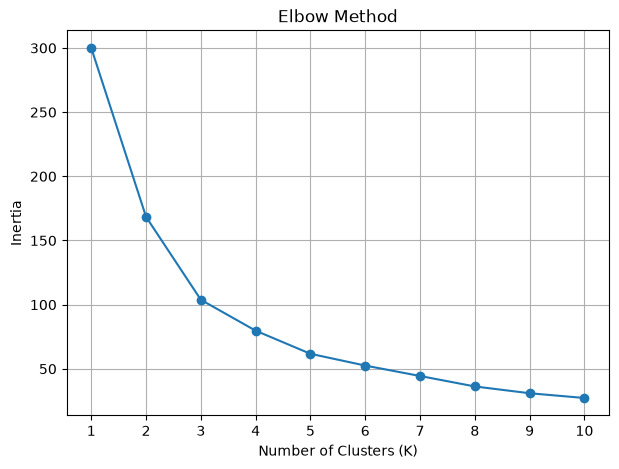


Inertia Values:
K = 1, Inertia = 300.00
K = 2, Inertia = 168.39
K = 3, Inertia = 103.79
K = 4, Inertia = 79.72
K = 5, Inertia = 61.71
K = 6, Inertia = 52.54
K = 7, Inertia = 44.41
K = 8, Inertia = 36.26
K = 9, Inertia = 30.97
K = 10, Inertia = 27.27


In [11]:
# Step 5: Plot the Elbow Graph
plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# Display inertia values
print("\nInertia Values:")
for k, value in enumerate(inertia, start=1):
    print(f"K = {k}, Inertia = {value:.2f}")



In [12]:
# Step 6: Apply K-Means with K = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_scaled)



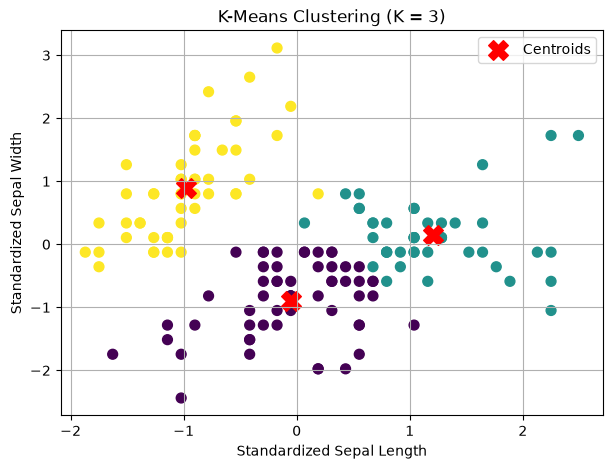

In [13]:
# Step 7: Visualize the Clusters
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

# Plot cluster centroids
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200,
    color='red',
    label='Centroids'
)

plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.title("K-Means Clustering (K = 3)")
plt.legend()
plt.grid(True)
plt.show()



In [14]:
# Step 8: Display Cluster Assignments
print("\nFirst 10 Cluster Assignments:")
print(clusters[:10])

# Display total inertia for K = 3
print("\nTotal Inertia for K = 3:")
print(kmeans.inertia_)

# Display cluster centroids
print("\nCluster Centroids:")
print(kmeans.cluster_centers_)



First 10 Cluster Assignments:
[2 2 2 2 2 2 2 2 2 2]

Total Inertia for K = 3:
103.78982520596084

Cluster Centroids:
[[-0.04825457 -0.89224112]
 [ 1.20144049  0.14411561]
 [-0.97822861  0.89321545]]
